# Activité pratique N°2 — Modèles génératifs (MNIST)

Suite du lab PyTorch. Dataset **MNIST** (28×28 = 784 pixels, chiffres 0–9).

1. Charger le dataset  
2. Modèle **discriminatif** (classifieur)  
3. **Auto-encodeur** simple + espace latent  
4. **VAE** (auto-encodeur variationnel)


## 0 — Device et imports


In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

try:
    from torcheval.metrics import MulticlassAccuracy
    HAS_TORCHEVAL = True
except ImportError:
    HAS_TORCHEVAL = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)
torch.manual_seed(1)


c:\Users\dell\Documents\projet_AIGenerative\tps\lab_mnist_v1\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Device : cpu


## 1 — Charger MNIST

`train=True` : 60 000 images. `train=False` : 10 000. `ToTensor` convertit en tenseur PyTorch. `DataLoader` organise des **batchs** de 128 images, `shuffle=True`.


In [2]:
transform = transforms.ToTensor()
train_dataset = datasets.MNIST(
    root="data", train=True, download=True, transform=transform
)
test_dataset = datasets.MNIST(
    root="data", train=False, download=True, transform=transform
)

batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print("Train :", len(train_dataset), "images")
print("Test  :", len(test_dataset), "images")


100.0%
100.0%
100.0%
100.0%


Train : 60000 images
Test  : 10000 images


Quelques images du premier batch (2 lignes × 5 colonnes).


Batch images : (128, 1, 28, 28) | labels : (128,)


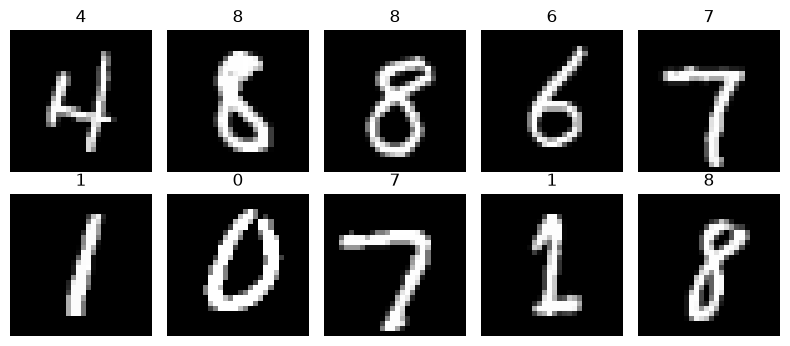

In [3]:
images, labels = next(iter(train_loader))
print("Batch images :", tuple(images.shape), "| labels :", tuple(labels.shape))

fig, axes = plt.subplots(2, 5, figsize=(8, 3.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(str(int(labels[i])))
    ax.axis("off")
plt.tight_layout()
plt.show()


## 2 — Modèle discriminatif (classifieur)

`Flatten` : 28×28 → 784. Couches `784 → 128 → 10`. Loss : **CrossEntropy**. Optimiseur : **Adam** (`lr=0.01`). 3 époques.


In [4]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.net(x)


clf = Classifier().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(clf.parameters(), lr=0.01)
print(clf)


Classifier(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [5]:
n_epochs = 3
clf.train()
for epoch in range(n_epochs):
    total_loss = 0.0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        pred = clf(x)
        loss = criterion(pred, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Époque {epoch + 1}/{n_epochs} — loss : {total_loss / len(train_loader):.4f}")


Époque 1/3 — loss : 0.2316
Époque 2/3 — loss : 0.1128
Époque 3/3 — loss : 0.0855


In [6]:
clf.eval()
correct, total = 0, 0
if HAS_TORCHEVAL:
    acc_metric = MulticlassAccuracy(num_classes=10)
with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        pred = clf(x).argmax(dim=1)
        correct += (pred == y).sum().item()
        total += y.size(0)
        if HAS_TORCHEVAL:
            acc_metric.update(pred, y)
acc = 100 * correct / total
print(f"Exactitude test : {acc:.2f} %")
if HAS_TORCHEVAL:
    print(f"Torcheval : {100 * float(acc_metric.compute()):.2f} %")


Exactitude test : 96.67 %
Torcheval : 96.67 %


## 3 — Auto-encodeur simple

Encodeur : 784 → 128 → 32 → **2** (code latent `z`). Décodeur : 2 → 32 → 128 → 784 + **Sigmoid**, puis `view` en 28×28. Loss : MSE entre l'entrée et la reconstruction. 5 époques.


In [7]:
class AutoEncodeur(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.encodeur = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 32),
            nn.ReLU(),
            nn.Linear(32, latent_dim),
        )
        self.decodeur = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid(),
        )

    def encode(self, x):
        return self.encodeur(x)

    def decode(self, z):
        return self.decodeur(z).view(-1, 1, 28, 28)

    def forward(self, x):
        z = self.encode(x)
        return self.decode(z)


latent_dim = 2
ae = AutoEncodeur(latent_dim).to(device)
ae_opt = torch.optim.Adam(ae.parameters(), lr=1e-3)
print(ae)


AutoEncodeur(
  (encodeur): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=2, bias=True)
  )
  (decodeur): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


In [8]:
n_epochs_ae = 5
ae.train()
for epoch in range(n_epochs_ae):
    total_loss = 0.0
    for x, _ in train_loader:
        x = x.to(device)
        x_hat = ae(x)
        loss = F.mse_loss(x_hat, x)
        ae_opt.zero_grad()
        loss.backward()
        ae_opt.step()
        total_loss += loss.item()
    print(f"Époque {epoch + 1}/{n_epochs_ae} — MSE : {total_loss / len(train_loader):.4f}")


Époque 1/5 — MSE : 0.0655
Époque 2/5 — MSE : 0.0519
Époque 3/5 — MSE : 0.0491
Époque 4/5 — MSE : 0.0465
Époque 5/5 — MSE : 0.0450


Reconstructions : ligne du haut = entrée, ligne du bas = sortie du décodeur.


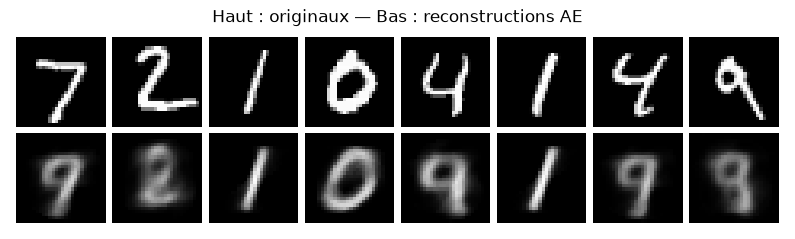

In [9]:
ae.eval()
x_test, _ = next(iter(test_loader))
x_test = x_test[:8].to(device)
with torch.no_grad():
    x_hat = ae(x_test)
comp = torch.cat([x_test.cpu(), x_hat.cpu()], dim=0)
grid = make_grid(comp, nrow=8, pad_value=1)
plt.figure(figsize=(10, 3))
plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray")
plt.axis("off")
plt.title("Haut : originaux — Bas : reconstructions AE")
plt.show()


Espace latent 2D : chaque image devient un point `(z1, z2)`, couleur = chiffre. Un AE simple mélange souvent les classes (confusion 7/2, etc.).


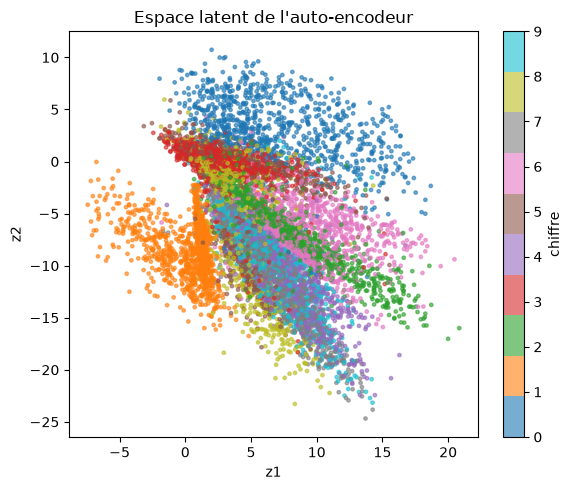

In [10]:
ae.eval()
zs, ys = [], []
with torch.no_grad():
    for x, y in test_loader:
        z = ae.encode(x.to(device)).cpu()
        zs.append(z)
        ys.append(y)
z_all = torch.cat(zs).numpy()
y_all = torch.cat(ys).numpy()

plt.figure(figsize=(6, 5))
sc = plt.scatter(z_all[:, 0], z_all[:, 1], c=y_all, cmap="tab10", s=6, alpha=0.6)
plt.colorbar(sc, ticks=range(10), label="chiffre")
plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Espace latent de l'auto-encodeur")
plt.tight_layout()
plt.show()


Génération : on tire un `z` au hasard et on demande au **décodeur** une image jamais vue.


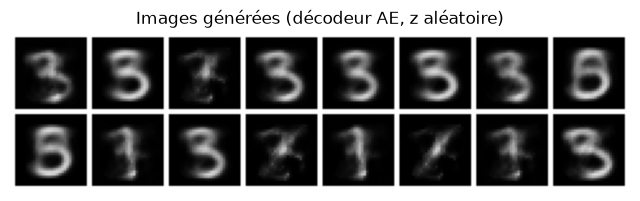

In [11]:
ae.eval()
with torch.no_grad():
    z_rand = torch.randn(16, latent_dim, device=device)
    samples = ae.decode(z_rand).cpu()
grid = make_grid(samples, nrow=8, pad_value=1)
plt.figure(figsize=(8, 3))
plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray")
plt.axis("off")
plt.title("Images générées (décodeur AE, z aléatoire)")
plt.show()


## 4 — VAE (auto-encodeur variationnel)

L'encodeur prédit `μ` et `log σ²`. Reparamétrisation : `z = μ + σ ⊙ ε`, `ε ~ N(0, I)`. Loss = reconstruction (BCE) + **KL** vers une gaussienne unitaire. L'espace latent est mieux organisé ; on peut échantillonner `z ~ N(0, I)`.


In [12]:
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 32),
            nn.ReLU(),
        )
        self.fc_mu = nn.Linear(32, latent_dim)
        self.fc_logvar = nn.Linear(32, latent_dim)
        self.dec = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid(),
        )

    def encode(self, x):
        h = self.enc(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparametrer(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return self.dec(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparametrer(mu, logvar)
        return self.decode(z), mu, logvar


def perte_vae(x_hat, x, mu, logvar):
    bce = F.binary_cross_entropy(x_hat.view(-1, 784), x.view(-1, 784), reduction="sum")
    kld = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return bce + kld, bce, kld


vae = VAE(latent_dim=2).to(device)
vae_opt = torch.optim.Adam(vae.parameters(), lr=1e-3)
print(vae)


VAE(
  (enc): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=32, bias=True)
    (4): ReLU()
  )
  (fc_mu): Linear(in_features=32, out_features=2, bias=True)
  (fc_logvar): Linear(in_features=32, out_features=2, bias=True)
  (dec): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


In [13]:
n_epochs_vae = 5
vae.train()
n_train = len(train_loader.dataset)
for epoch in range(n_epochs_vae):
    total = 0.0
    for x, _ in train_loader:
        x = x.to(device)
        x_hat, mu, logvar = vae(x)
        loss, _, _ = perte_vae(x_hat, x, mu, logvar)
        vae_opt.zero_grad()
        loss.backward()
        vae_opt.step()
        total += loss.item()
    print(f"Époque {epoch + 1}/{n_epochs_vae} — loss : {total / n_train:.2f}")


Époque 1/5 — loss : 205.67
Époque 2/5 — loss : 172.63
Époque 3/5 — loss : 166.82
Époque 4/5 — loss : 163.50
Époque 5/5 — loss : 160.80


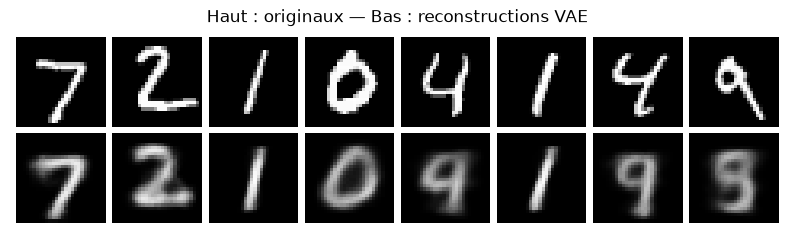

In [14]:
vae.eval()
x_test, _ = next(iter(test_loader))
x_test = x_test[:8].to(device)
with torch.no_grad():
    x_hat, _, _ = vae(x_test)
comp = torch.cat([x_test.cpu(), x_hat.cpu()], dim=0)
grid = make_grid(comp, nrow=8, pad_value=1)
plt.figure(figsize=(10, 3))
plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray")
plt.axis("off")
plt.title("Haut : originaux — Bas : reconstructions VAE")
plt.show()


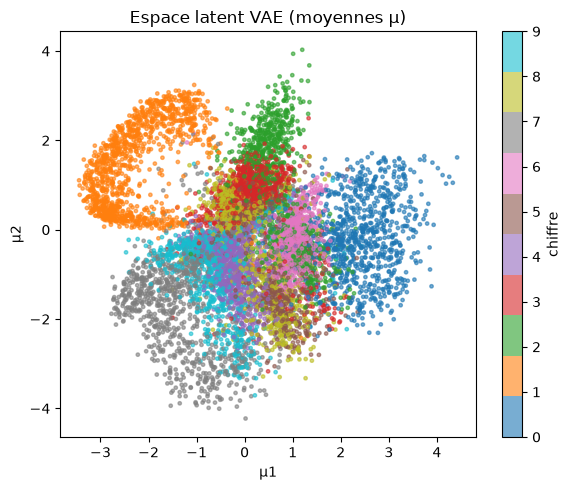

In [15]:
vae.eval()
zs, ys = [], []
with torch.no_grad():
    for x, y in test_loader:
        mu, _ = vae.encode(x.to(device))
        zs.append(mu.cpu())
        ys.append(y)
z_all = torch.cat(zs).numpy()
y_all = torch.cat(ys).numpy()

plt.figure(figsize=(6, 5))
sc = plt.scatter(z_all[:, 0], z_all[:, 1], c=y_all, cmap="tab10", s=6, alpha=0.6)
plt.colorbar(sc, ticks=range(10), label="chiffre")
plt.xlabel("μ1")
plt.ylabel("μ2")
plt.title("Espace latent VAE (moyennes μ)")
plt.tight_layout()
plt.show()


Échantillons VAE : `z ~ N(0, I)` passé dans le décodeur.


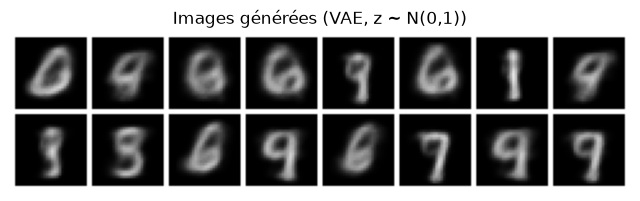

In [16]:
vae.eval()
with torch.no_grad():
    z_rand = torch.randn(16, 2, device=device)
    samples = vae.decode(z_rand).cpu()
grid = make_grid(samples, nrow=8, pad_value=1)
plt.figure(figsize=(8, 3))
plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray")
plt.axis("off")
plt.title("Images générées (VAE, z ~ N(0,1))")
plt.show()
